<a href="https://colab.research.google.com/github/pritum120753/CSE4345-Big-Data-Analytics-Notes/blob/main/ML_Project_Pritum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cell 1 — Install XAI Libraries

In [ ]:
!pip install shap lime streamlit pyngrok -q

import shap
import lime
import lime.lime_tabular
import joblib

print("✅ All installed!")

✅ All installed!


Cell 2 — Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import lime
import lime.lime_tabular
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import warnings
warnings.filterwarnings('ignore')

print("✅ All libraries imported!")

✅ All libraries imported!


Cell 3 — Load & Prepare Dataset

In [ ]:
import random
import numpy as np
random.seed(42)

url = "https://raw.githubusercontent.com/dsrscientist/dataset1/master/heart_disease.csv"
df = pd.read_csv(url)

synthetic_data = []
for _ in range(5000):
    age      = random.randint(25, 80)
    sex      = random.randint(0, 1)
    cp       = random.randint(0, 3)
    trestbps = random.randint(90, 200)
    chol     = random.randint(150, 450)
    fbs      = random.randint(0, 1)
    restecg  = random.randint(0, 2)
    thalach  = random.randint(70, 210)
    exang    = random.randint(0, 1)
    oldpeak  = round(random.uniform(0, 6), 1)
    slope    = random.randint(0, 2)
    ca       = random.randint(0, 3)
    thal     = random.randint(0, 3)

    risk = 0
    if age > 55: risk += 1
    if sex == 1: risk += 1
    if cp in [2, 3]: risk += 1
    if trestbps > 140: risk += 1
    if chol > 240: risk += 1
    if thalach < 140: risk += 1
    if exang == 1: risk += 1
    if oldpeak > 2: risk += 1
    if ca > 0: risk += 1

    target = 1 if risk >= 4 else 0

    synthetic_data.append({
        'age': age, 'sex': sex, 'cp': cp,
        'trestbps': trestbps, 'chol': chol, 'fbs': fbs,
        'restecg': restecg, 'thalach': thalach, 'exang': exang,
        'oldpeak': oldpeak, 'slope': slope, 'ca': ca,
        'thal': thal, 'target': target
    })

df_synthetic = pd.DataFrame(synthetic_data)

for col in ['chol', 'trestbps', 'thalach']:
    idx = df_synthetic.sample(50).index
    df_synthetic.loc[idx, col] = None

df_combined = pd.concat([df, df_synthetic], ignore_index=True)
df_combined['chol'].fillna(df_combined['chol'].median(), inplace=True)
df_combined['trestbps'].fillna(df_combined['trestbps'].median(), inplace=True)
df_combined['thalach'].fillna(df_combined['thalach'].median(), inplace=True)

X = df_combined.drop('target', axis=1)
y = df_combined['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f"Original: 303 | Synthetic: 5000 | Total: {df_combined.shape[0]}")
print(f"Missing values after cleaning: {df_combined.isnull().sum().sum()}")
print(f"Train: {X_train.shape[0]} | Test: {X_test.shape[0]}")
print("✅ Dataset ready!")

Original: 303 | Synthetic: 5000 | Total: 5303
Missing values after cleaning: 0
Train: 4242 | Test: 1061
✅ Dataset ready!


Cell 4 — Train Random Forest & XGBoost  Model

In [ ]:
from xgboost import XGBClassifier

# Train Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)
y_pred_rf = rf_model.predict(X_test_scaled)

# Train XGBoost — best model from companion project
xgb_model = XGBClassifier(random_state=42, eval_metric='logloss')
xgb_model.fit(X_train_scaled, y_train)
y_pred_xgb = xgb_model.predict(X_test_scaled)

# Use XGBoost as main model
y_pred = y_pred_xgb

print("✅ XGBoost model trained! (from companion project)")
print(f"\nModel Performance:")
print(f"Accuracy  : {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"Precision : {precision_score(y_test, y_pred)*100:.2f}%")
print(f"Recall    : {recall_score(y_test, y_pred)*100:.2f}%")
print(f"F1-Score  : {f1_score(y_test, y_pred)*100:.2f}%")

✅ XGBoost model trained! (from companion project)

Model Performance:
Accuracy  : 93.12%
Precision : 94.35%
Recall    : 97.48%
F1-Score  : 95.89%


Cell 5 — SHAP Global Feature Importance

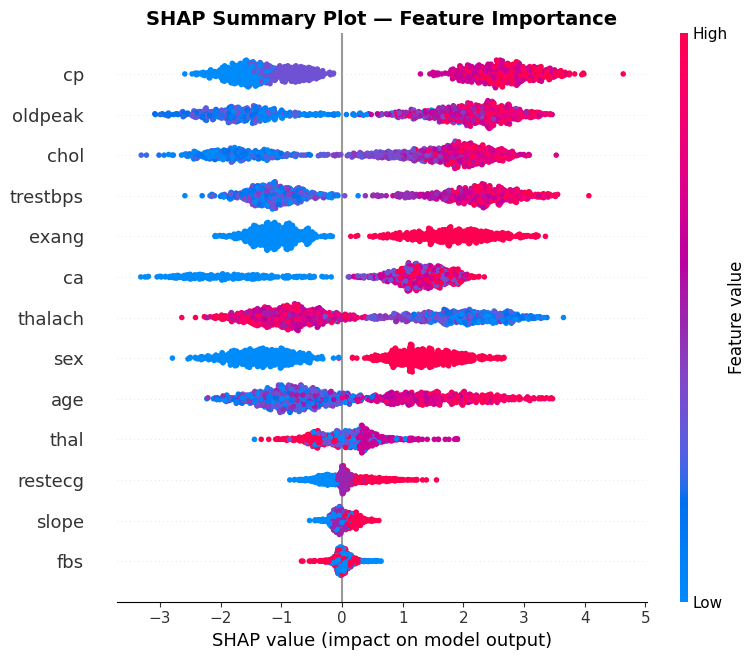

✅ SHAP Summary Plot saved!


In [ ]:
# SHAP Explainer for XGBoost
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_scaled)

# Global Feature Importance — Summary Plot
plt.figure(figsize=(10, 7))
shap.summary_plot(
    shap_values,
    X_test_scaled,
    feature_names=X.columns.tolist(),
    show=False
)
plt.title("SHAP Summary Plot — Feature Importance", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ SHAP Summary Plot saved!")

Cell 6 — SHAP Waterfall Plot (Single Patient)

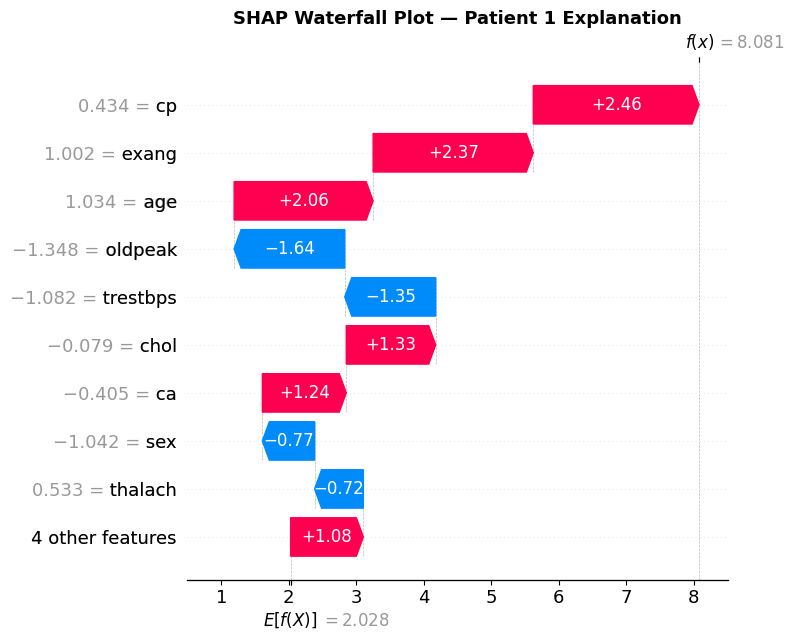

✅ SHAP Waterfall Plot saved!


In [ ]:
# SHAP Waterfall Plot for XGBoost
shap_exp = shap.Explanation(
    values=shap_values,
    base_values=explainer.expected_value,
    data=X_test_scaled,
    feature_names=X.columns.tolist()
)

# Pick patient index 0
plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_exp[0], show=False)
plt.title("SHAP Waterfall Plot — Patient 1 Explanation", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_waterfall.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ SHAP Waterfall Plot saved!")

Cell 7 — SHAP Bar Plot (Global)

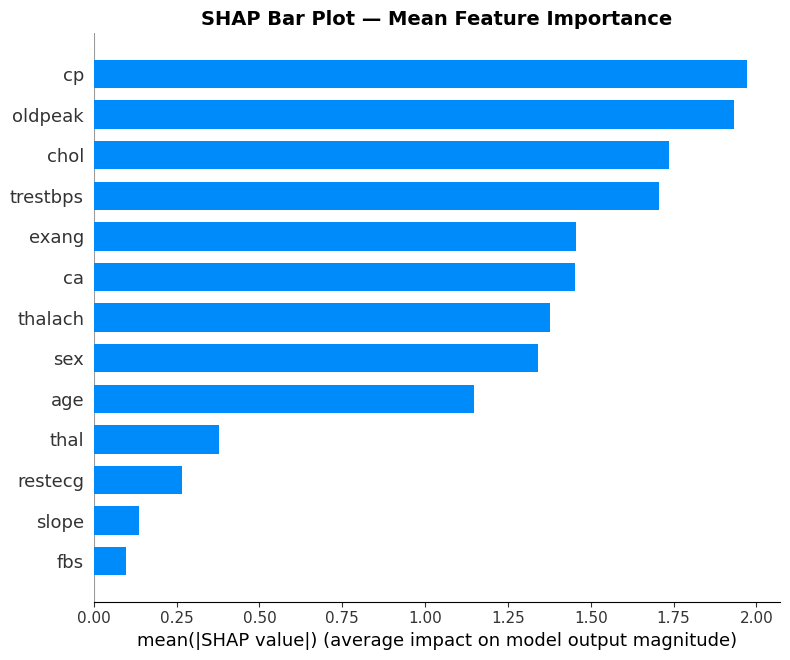

✅ SHAP Bar Plot saved!


In [ ]:
# SHAP Bar Plot for XGBoost
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values,
    X_test_scaled,
    feature_names=X.columns.tolist(),
    plot_type="bar",
    show=False
)
plt.title("SHAP Bar Plot — Mean Feature Importance", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_bar.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ SHAP Bar Plot saved!")

Cell 8 — LIME Explanation

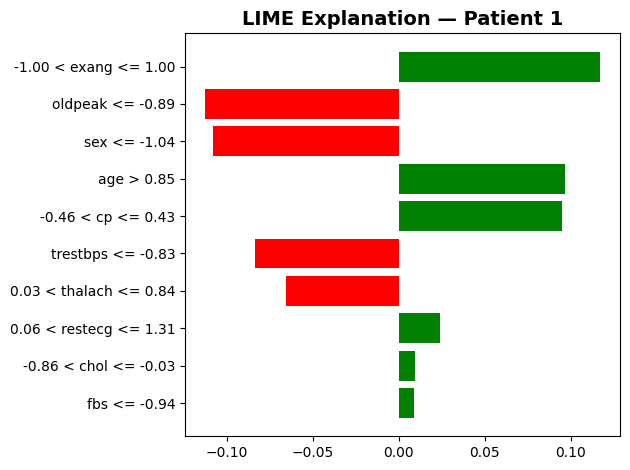

✅ LIME Explanation saved!


In [ ]:
# LIME Explainer for XGBoost
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    X_train_scaled,
    feature_names=X.columns.tolist(),
    class_names=['No Disease', 'Disease'],
    mode='classification'
)

# Explain Patient 1
lime_exp = lime_explainer.explain_instance(
    X_test_scaled[0],
    xgb_model.predict_proba,
    num_features=10
)

# Plot
fig = lime_exp.as_pyplot_figure()
plt.title("LIME Explanation — Patient 1", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('lime_explanation.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ LIME Explanation saved!")

Cell 9 — SHAP vs LIME Comparison Table

In [ ]:
# SHAP top features for XGBoost
shap_importance = pd.Series(
    np.abs(shap_values).mean(axis=0),
    index=X.columns.tolist()
).sort_values(ascending=False)

# LIME top features — fixed parsing
lime_features = lime_exp.as_list()
lime_dict = {}
for feat_str, val in lime_features:
    for col in X.columns.tolist():
        if col in feat_str:
            lime_dict[col] = abs(val)
            break

lime_importance = pd.Series(lime_dict).sort_values(ascending=False)

# Comparison table
print("=" * 50)
print("   SHAP vs LIME — Top Feature Comparison")
print("=" * 50)
print(f"\n{'Rank':<6} {'SHAP Feature':<15} {'LIME Feature':<15}")
print("-" * 45)
for i in range(5):
    shap_f = shap_importance.index[i]
    lime_f = lime_importance.index[i] if i < len(lime_importance) else "-"
    print(f"{i+1:<6} {shap_f:<15} {lime_f:<15}")

print("\n✅ Comparison done!")
print(f"\nSHAP Top Feature : {shap_importance.index[0]}")
print(f"LIME Top Feature : {lime_importance.index[0]}")

   SHAP vs LIME — Top Feature Comparison

Rank   SHAP Feature    LIME Feature   
---------------------------------------------
1      cp              exang          
2      oldpeak         oldpeak        
3      chol            sex            
4      trestbps        age            
5      exang           cp             

✅ Comparison done!

SHAP Top Feature : cp
LIME Top Feature : exang


Cell 10 — SHAP vs LIME Visual Comparison

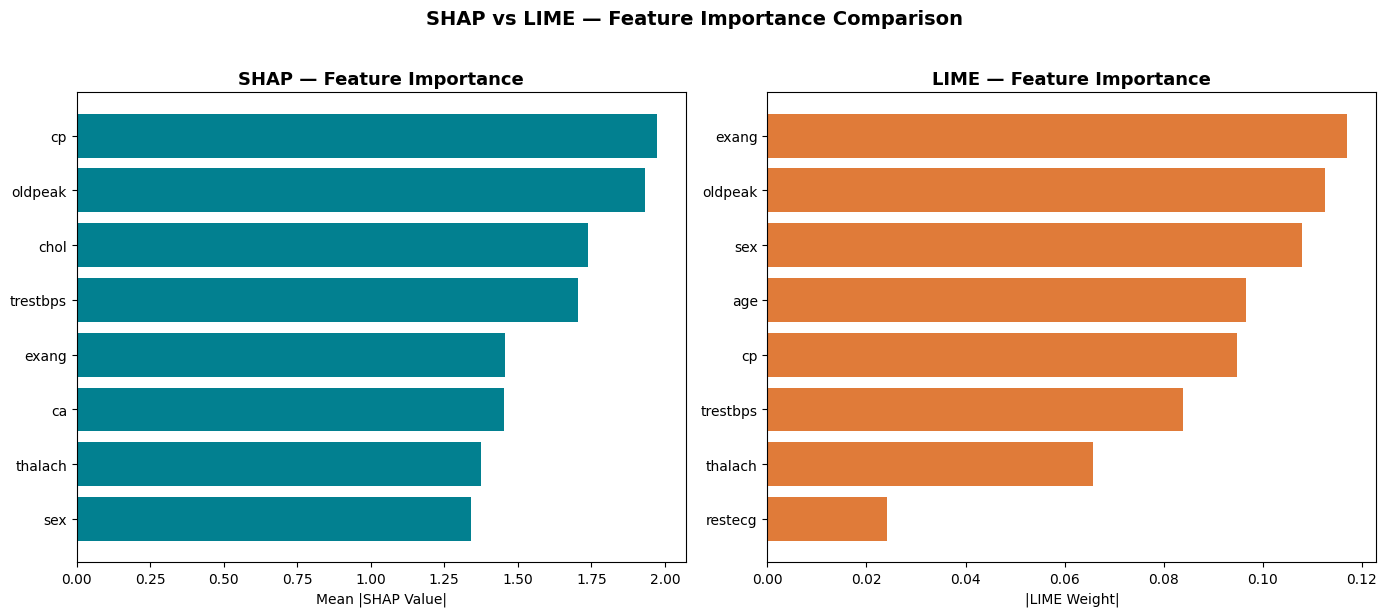

✅ SHAP vs LIME comparison chart saved!


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# SHAP Bar
axes[0].barh(shap_importance.index[:8][::-1],
             shap_importance.values[:8][::-1],
             color='#028090')
axes[0].set_title('SHAP — Feature Importance', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Mean |SHAP Value|')

# LIME Bar
axes[1].barh(lime_importance.index[:8][::-1],
             lime_importance.values[:8][::-1],
             color='#E07B39')
axes[1].set_title('LIME — Feature Importance', fontsize=13, fontweight='bold')
axes[1].set_xlabel('|LIME Weight|')

plt.suptitle('SHAP vs LIME — Feature Importance Comparison',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('shap_vs_lime.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ SHAP vs LIME comparison chart saved!")

Cell 11 — Save Model & Scaler

In [ ]:
joblib.dump(xgb_model, 'xgb_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

from google.colab import files
files.download('xgb_model.pkl')
files.download('scaler.pkl')

print("✅ XGBoost model saved & downloaded!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ XGBoost model saved & downloaded!


Cell 12 — Create Streamlit App

In [ ]:
dashboard_code = '''
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt

model = joblib.load("xgb_model.pkl")
scaler = joblib.load("scaler.pkl")

st.set_page_config(page_title="Heart Disease XAI", page_icon="❤️", layout="wide")
st.title("❤️ Heart Disease Prediction & Explanation")
st.markdown("### Explainable AI Dashboard — SHAP + LIME")
st.markdown("---")

feature_names = ["age","sex","cp","trestbps","chol","fbs",
                 "restecg","thalach","exang","oldpeak","slope","ca","thal"]

st.sidebar.header("Patient Information")
age      = st.sidebar.selectbox("Age", list(range(20, 81)), index=30)
sex      = st.sidebar.selectbox("Sex", [0,1], format_func=lambda x: "Female" if x==0 else "Male")
cp       = st.sidebar.selectbox("Chest Pain Type (0-3)", [0,1,2,3])
trestbps = st.sidebar.selectbox("Resting Blood Pressure", list(range(80, 201, 5)), index=8)
chol     = st.sidebar.selectbox("Cholesterol", list(range(100, 601, 10)), index=14)
fbs      = st.sidebar.selectbox("Fasting Blood Sugar > 120", [0,1], format_func=lambda x: "No" if x==0 else "Yes")
restecg  = st.sidebar.selectbox("Resting ECG (0-2)", [0,1,2])
thalach  = st.sidebar.selectbox("Max Heart Rate", list(range(60, 221, 5)), index=18)
exang    = st.sidebar.selectbox("Exercise Induced Angina", [0,1], format_func=lambda x: "No" if x==0 else "Yes")
oldpeak  = st.sidebar.selectbox("ST Depression", [round(x*0.5,1) for x in range(0,13)], index=2)
slope    = st.sidebar.selectbox("Slope (0-2)", [0,1,2])
ca       = st.sidebar.selectbox("Major Vessels (0-3)", [0,1,2,3])
thal     = st.sidebar.selectbox("Thal (0-3)", [0,1,2,3])

input_data = np.array([[age, sex, cp, trestbps, chol, fbs,
                         restecg, thalach, exang, oldpeak, slope, ca, thal]])
input_scaled = scaler.transform(input_data)

pred = model.predict(input_scaled)[0]
prob = model.predict_proba(input_scaled)[0][1]

if pred == 1:
    st.error(f"⚠️ Heart Disease Detected — Probability: {prob*100:.1f}%")
else:
    st.success(f"✅ No Heart Disease — Probability: {prob*100:.1f}%")

st.markdown(f"**Prediction Confidence: {max(prob, 1-prob)*100:.1f}%**")
st.markdown("---")

st.subheader("🔵 SHAP Explanation")
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(input_scaled)
fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#E07B39" if v > 0 else "#028090"
          for v in shap_values[0]]
ax.barh(feature_names, shap_values[0], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("SHAP Value (Orange = Disease, Teal = No Disease)")
ax.set_title("Feature Impact on Prediction")
st.pyplot(fig)
plt.close()

st.markdown("---")
st.subheader("📋 Patient Data Summary")
feature_df = pd.DataFrame({
    "Feature": feature_names,
    "Value": input_data[0]
})
st.table(feature_df)
'''

with open('app.py', 'w') as f:
    f.write(dashboard_code)

print("✅ app.py updated!")

✅ app.py updated!


Cell 13 — Run Streamlit Dashboard

In [ ]:
!npm install -g localtunnel -q
!pip install streamlit -q

import subprocess
import time

# Kill old processes
import os
os.system("pkill -f streamlit")
os.system("pkill -f lt")
time.sleep(2)

# Run streamlit
subprocess.Popen(
    ["streamlit", "run", "app.py", "--server.port=8501", "--server.headless=true"],
    stdout=subprocess.PIPE, stderr=subprocess.PIPE
)
time.sleep(5)

# localtunnel
lt = subprocess.Popen(
    ["lt", "--port", "8501"],
    stdout=subprocess.PIPE, stderr=subprocess.PIPE
)
time.sleep(4)

output = lt.stdout.readline().decode()
print(output)
print("✅ Copy the URL and open in browser!")
print("🔑 Password: https://loca.lt/mytunnelpassword")

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇
changed 22 packages in 5s
⠇
⠇3 packages are looking for funding
⠇  run `npm fund` for details
⠇your url is: https://sixty-memes-carry.loca.lt

✅ Copy the URL and open in browser!
🔑 Password: https://loca.lt/mytunnelpassword
